# 05 — Correlated Monte Carlo gameweek simulator

`src/simulator.py` turns each point forecast into a full distribution:

1. **Minutes:** draw 0 / 1–59 / 60+ from the minutes model, injury flags included.
2. **Points:** for 60+ minutes, blank or return. P(blank) falls smoothly as the forecast rises, and returns are rescaled so the mean equals the forecast exactly.
3. **Correlation:** teammates share two team factors, like sector factors for stocks. The *defence* factor is clean sheets; the *attack* factor is team goals.

Everything below is validated walk-forward: fit on earlier gameweeks only, then simulate the next one.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

bt = pd.read_csv("../data/sim_backtest.csv")
players = pd.read_csv("../data/sim_backtest_players.csv")
bt.groupby("correlated")[["coverage", "coverage_played", "pit_mean", "team_coverage", "team_std_ratio"]].mean().round(3)

,coverage,coverage_played,pit_mean,team_coverage,team_std_ratio
correlated,,,,,
False,0.912,0.801,0.498,0.595,1.411
True,0.912,0.800,0.499,0.829,0.878


- **`coverage_played`** is the share of players who played whose score landed inside the simulated 80% interval. Target 0.80.
- **`pit_mean`** is where the actual score falls in its simulated distribution, on average. Target 0.50.
- **`team_coverage`** is the same 80% test for each team's total points, and it shows why correlation matters. With players treated as independent (`False`), only ~60% of team totals land in the interval, and real team totals swing ~40% more than simulated (`team_std_ratio`). The two factors bring coverage to ~83%.

## 1. Probability integral transform (PIT)

If the simulated distributions are right, the actual scores' positions within them are uniform: a flat histogram. A U shape would mean the distributions are too narrow, a hump too wide.
Many outcomes tie exactly (0 for benched players, 2 for blanks), so each player-gameweek gets a **randomised PIT**: a uniform draw between P(sim < actual) and P(sim ≤ actual).
It covers every player, because looking only at those who played would bias the PIT upwards: their simulations still include the benched outcomes.

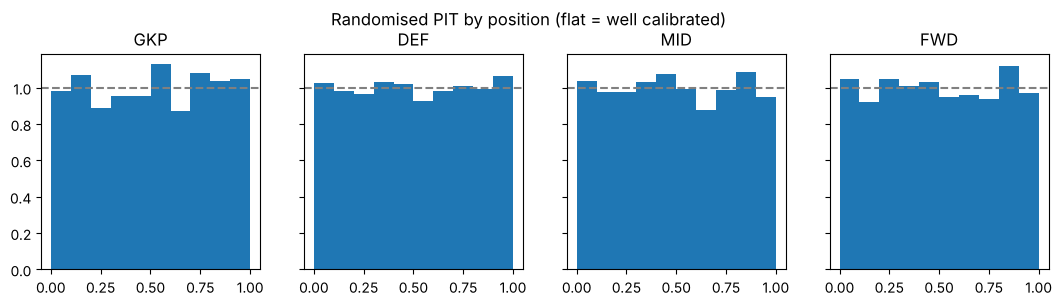

In [2]:
rng = np.random.default_rng(0)
rpit = players["pit_lo"] + rng.random(len(players)) * (players["pit_hi"] - players["pit_lo"])
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, pos in zip(axes, ["GKP", "DEF", "MID", "FWD"]):
    ax.hist(rpit[players["position"] == pos], bins=10, density=True)
    ax.axhline(1, ls="--", c="grey")
    ax.set_title(pos)
fig.suptitle("Randomised PIT by position (flat = well calibrated)", y=1.04)
plt.show()

## 2. Tails: blanks and hauls

Blanks (≤2 points) and hauls (10+) drive captaincy and differential decisions. Forecast probability against how often it really happened:

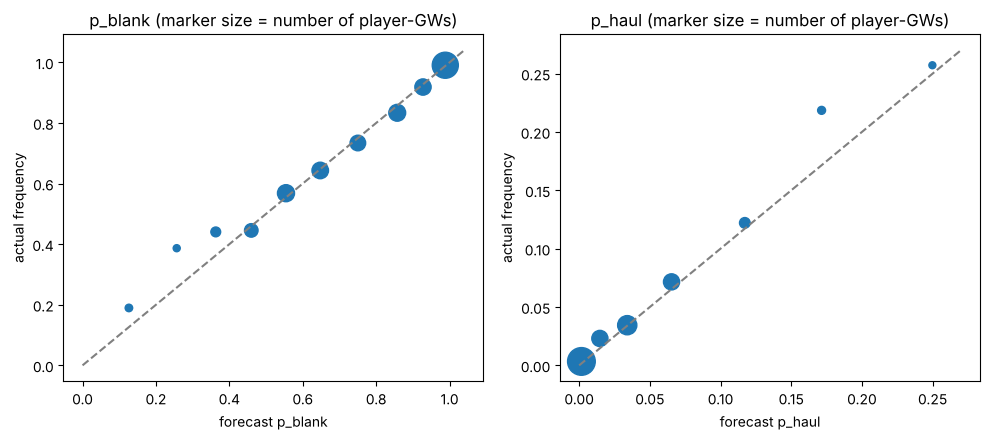

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (col, hit, bins) in zip(axes, [
    ("p_blank", players["actual"] <= 2, [0, .2, .3, .4, .5, .6, .7, .8, .9, .95, 1]),
    ("p_haul", players["actual"] >= 10, [0, .01, .02, .05, .1, .15, .2, .3, .5]),
]):
    cal = (pd.DataFrame({"f": players[col], "a": hit})
           .groupby(pd.cut(players[col], bins, include_lowest=True), observed=True)
           .agg(f=("f", "mean"), a=("a", "mean"), n=("a", "size")))
    cal = cal[cal["n"] >= 30]
    ax.scatter(cal["f"], cal["a"], s=np.sqrt(cal["n"]) * 3)
    lim = max(cal["f"].max(), cal["a"].max()) * 1.05
    ax.plot([0, lim], [0, lim], ls="--", c="grey")
    ax.set_xlabel(f"forecast {col}")
    ax.set_ylabel("actual frequency")
    ax.set_title(col + " (marker size = number of player-GWs)")
plt.tight_layout()
plt.show()

## 3. Team factor loadings

These are fitted from how teammates' scores move together. Goalkeepers and defenders load on **defence** (clean sheets); midfielders and forwards load on **attack**.

In [4]:
from baseline_model import add_period
from simulator import simulate_next

panel = add_period(pd.read_csv("../data/player_gw_panel.csv"))
summary, sims, sim = simulate_next(panel)
sim.loadings.round(3)

,defence,attack
GKP,0.825,0.167
DEF,0.714,0.174
MID,0.141,0.293
FWD,-0.090,0.416


## 4. Fan chart for the upcoming gameweek

Each bar spans the 10th–90th percentile, and the dot is the mean. Players with similar expected points can carry very different risk.

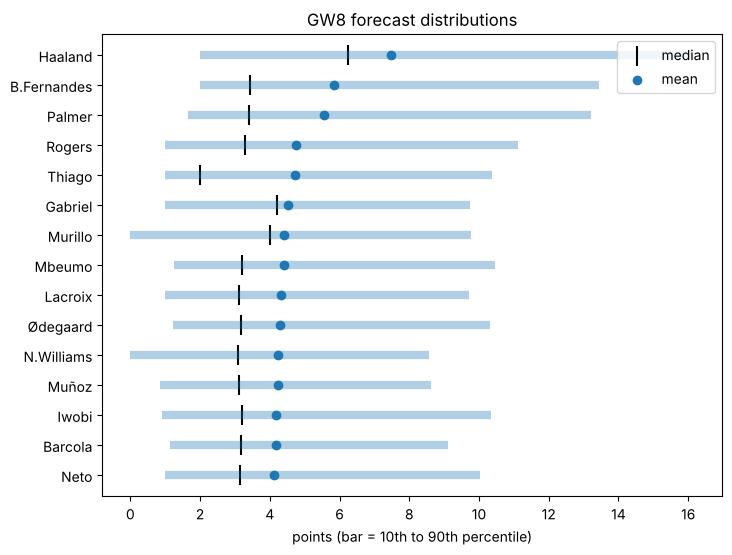

,web_name,position,price_m,p_play,xpts,std,p10,p50,p90,p_blank,p_haul
202,Haaland,FWD,15.7,0.99,7.47,5.42,2.00,6.25,16.17,0.31,0.32
61,B.Fernandes,MID,11.8,0.99,5.84,4.68,2.00,3.43,13.45,0.27,0.18
256,Palmer,MID,9.8,0.98,5.55,4.57,1.64,3.40,13.20,0.30,0.18
255,Rogers,MID,8.0,0.95,4.74,4.16,1.00,3.30,11.11,0.38,0.11
463,Thiago,FWD,7.8,0.94,4.73,4.45,1.00,2.00,10.37,0.58,0.15
212,Gabriel,DEF,7.9,0.98,4.51,3.73,1.00,4.21,9.74,0.39,0.07
569,Murillo,DEF,5.5,0.95,4.42,3.76,0.00,4.02,9.78,0.40,0.07
324,Mbeumo,MID,7.9,0.96,4.40,3.77,1.27,3.21,10.47,0.41,0.11
293,Lacroix,DEF,5.9,0.97,4.33,3.74,1.00,3.10,9.72,0.42,0.06
114,Ødegaard,MID,6.8,0.96,4.31,3.73,1.22,3.19,10.30,0.43,0.11


In [5]:
top = summary.sort_values("xpts", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.hlines(top["web_name"], top["p10"], top["p90"], lw=6, alpha=0.35)
ax.scatter(top["p50"], top["web_name"], marker="|", s=200, c="k", label="median")
ax.scatter(top["xpts"], top["web_name"], zorder=3, label="mean")
ax.set_xlabel("points (bar = 10th to 90th percentile)")
ax.set_title(f"GW{int(summary['round'].iloc[0])} forecast distributions")
ax.legend()
plt.show()
summary.sort_values("xpts", ascending=False)[
    ["web_name", "position", "price_m", "p_play", "xpts", "std", "p10", "p50", "p90", "p_blank", "p_haul"]
].head(15).round(2)

## 5. Captaincy is a leveraged bet

The captain's points count double. From the same 10,000 simulated gameweeks, here's how often each candidate is the top scorer among them, and how often doubling them returns 20+ points.
Mean points alone hide this.

In [6]:
cands = summary.sort_values("xpts", ascending=False).head(6).index
c_sims = sims[:, cands]
best = np.bincount(c_sims.argmax(axis=1), minlength=len(cands)) / len(c_sims)
pd.DataFrame({
    "player": summary.loc[cands, "web_name"].to_numpy(),
    "xpts": summary.loc[cands, "xpts"].round(2).to_numpy(),
    "P(top scorer of these)": best.round(3),
    "P(captain >= 20 pts)": (2 * c_sims >= 20).mean(axis=0).round(3),
    "P(captain <= 4 pts)": (2 * c_sims <= 4).mean(axis=0).round(3),
})

,player,xpts,P(top scorer of these),P(captain >= 20 pts),P(captain <= 4 pts)
0,Haaland,7.47,0.310,0.318,0.310
1,B.Fernandes,5.84,0.180,0.184,0.268
2,Palmer,5.55,0.151,0.178,0.301
3,Rogers,4.74,0.114,0.112,0.381
4,Thiago,4.73,0.135,0.152,0.584
5,Gabriel,4.51,0.110,0.068,0.388


## 6. Concentration risk: tripling up on one defence

Compare three defenders from **one** team against three defenders from **three different** teams with similar expected points.
The means are about equal, but the same-team trio's total is far more volatile, because clean sheets arrive together or not at all.

In [7]:
defs = summary[(summary["position"] == "DEF") & (summary["p_play"] > 0.9)].sort_values("xpts", ascending=False)
team_counts = defs.groupby("team").size()
stack_team = defs[defs["team"].isin(team_counts[team_counts >= 3].index)].groupby("team")["xpts"].apply(lambda s: s.head(3).sum()).idxmax()
stack = defs[defs["team"] == stack_team].head(3)
spread = defs[~defs["team"].isin([stack_team])].drop_duplicates("team")
spread = spread.iloc[(spread["xpts"] - stack["xpts"].mean()).abs().argsort()[:3]]

rows = []
for name, trio in (("same team", stack), ("three teams", spread)):
    total = sims[:, trio.index].sum(axis=1)
    rows.append({"trio": name, "players": ", ".join(trio["web_name"]), "mean": total.mean(),
                 "std": total.std(), "P(total <= 6)": (total <= 6).mean(), "P(total >= 25)": (total >= 25).mean()})
pd.DataFrame(rows).round(3)

,trio,players,mean,std,P(total <= 6),P(total >= 25)
0,same team,"Murillo, N.Williams, Muñoz",12.871,8.607,0.219,0.086
1,three teams,"Lacroix, Bogle, Gabriel",12.939,6.368,0.117,0.042


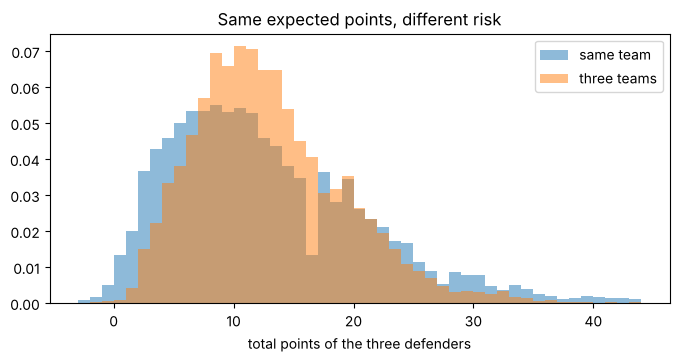

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, trio in (("same team", stack), ("three teams", spread)):
    ax.hist(sims[:, trio.index].sum(axis=1), bins=np.arange(-3, 45), alpha=0.5, density=True, label=name)
ax.set_xlabel("total points of the three defenders")
ax.set_title("Same expected points, different risk")
ax.legend()
plt.show()

## Caveats and next steps

- **Opponent effects are left out.** When our attack scores, their defence concedes, and that negative correlation would matter if you own players on both sides of one fixture.
- **One gameweek at a time.** Extending to multi-gameweek and season horizons needs features rolled forward through future fixtures.
- **Next: the mean-variance squad optimizer (Layer 3).** Pick the 15 players that maximise expected points minus a risk penalty, under the £100m budget, position limits and max 3 per club, using these simulated scenarios as the risk model.